# CUSTOMER CHURN PREDICTION fOR IBM (TELECOMMUNICATIONS COMPANY)


# 1.0 BUSINESS UNDERSTANDING

## 1.1 PROBLEM STATEMENT

IBM wants to reduce customer churn by identifting customers who are likely to leave. High churn rates reduce revenue, increase customer acqusition costs and hinder business growth.
IBM has historical customer data containing demographics, contract types, internet services, payment, tenure, monthly charges and churn status. 
The management needs a predictive system that can flag customers ar risk of churning so they can intervene with retention strategies.

## 1.2 BUSINESS QUESTION

- Can a machine learning be used to predict whether a customer will churn based on their characteristics and service information?

## 1.3 OBJECTIVES

**Main objective**: To develop a predictive model that accurately predicts a customer to churn and deploy it.

- Other objectives are; Conduct an in-depth analysis of the dataset to identify key features that impact customers churning in IBM.
  

# 2.0 Understanding the dataset

The dataset contains historical customer information from IBM company. Each row represents a customer and each column represents a customer attribute such as:

- Demographics (gender, senior citizen, partner, dependents)

- Contract type (month-to-month, one year, two year)

- Internet service (DSL, fiber optic, none)

- Payment method (electronic check, mailed check, bank transfer, credit card)

- Tenure (number of months with the company)

- Monthly charges and total charges

- Subscribed services (online security, tech support, streaming TV, etc.)

- Churn status (target variable: Yes/No)



## 2.1 Imports needed

In [1]:
# ! pip install -r requirements.txt

In [44]:
# imports needed for the project
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

## 2.3 Inspect and  Load the dataset

In [3]:
# load the dataset
df_raw = pd.read_csv("IBM Telco Customer churn.csv") # the original dataset
df = df_raw.copy() # data to use for analysis
display(df_raw.head())
display(df_raw.tail())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [4]:
# Check the shape of the dataset
print(f'The dataset has  {df.shape[0]} rows and {df.shape[1]} columns')

The dataset has  7043 rows and 21 columns


In [5]:
# check column types
print("\n=== Column Types ===")
print(df.dtypes)


=== Column Types ===
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [6]:
# Summary of the dataset
# in terms of missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
# check for duplicates 
n_dupes = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {n_dupes}")



Number of duplicate rows: 0


In [8]:
# The target variable is 'Churn', which indicates whether a customer has churned or not. Let's check the distribution of this variable.
print("\n=== Churn Distribution ===")
churn_counts = df['Churn'].value_counts() * 100 / len(df)
print(churn_counts)


=== Churn Distribution ===
Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


- The dataset has 7043 rows and 21 columns.
- The dataset has no duplicates 
- It has no missing values 
- It has 3 numerical columns 
- It has 9 categorical columns
- Though some data columns has unfit data types like *Total charges* which should be a numerical data type(int64).
- Senior_citizen is also encode hence it being a categorical feature(0 not bieng a senior citizen, 1 being senior citizen).
- The target variable(Churn) is a string/object and the is an imbalance whereby 73% of the customers do not churn while 26% of the customers want to leave.
- The customer ID for prediction because it behaves as index doesn't really influence the target variable in any way( should be dropped).

# 3.0 Data preparation and cleaning

In [9]:
# Drop unnecessary columns
df.drop(columns='customerID', inplace=True, errors='ignore')

# correct data type for 'TotalCharges' column
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Convert senior citizen from 0/1  to Yes/No for clear visuals in EDA
df['SeniorCitizen'] = df['SeniorCitizen'].map({1:'Yes', 0: 'No'})

In [10]:
# check missing values
df.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
# drop the missing values in Total charges 
df = df.dropna()
df.info() 

<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   str    
 1   SeniorCitizen     7032 non-null   str    
 2   Partner           7032 non-null   str    
 3   Dependents        7032 non-null   str    
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   str    
 6   MultipleLines     7032 non-null   str    
 7   InternetService   7032 non-null   str    
 8   OnlineSecurity    7032 non-null   str    
 9   OnlineBackup      7032 non-null   str    
 10  DeviceProtection  7032 non-null   str    
 11  TechSupport       7032 non-null   str    
 12  StreamingTV       7032 non-null   str    
 13  StreamingMovies   7032 non-null   str    
 14  Contract          7032 non-null   str    
 15  PaperlessBilling  7032 non-null   str    
 16  PaymentMethod     7032 non-null   str    
 17  MonthlyChar

In [12]:
# check for duplicates 
n_dupes = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {n_dupes}")

# remove the duplicates
df = df.drop_duplicates()
print(f"\nNumber of rows after removing duplicates: {df.shape[0]}")


Number of duplicate rows: 22

Number of rows after removing duplicates: 7010


In [13]:
# check for missing values again
missing_values = df.isna().sum()
print("\n=== Missing Values After Cleaning ===")
print(f"\nNumber of missing values after cleaning: {missing_values.sum()}")

# check for duplicates again
n_dupes = df.duplicated().sum()
print(f"\nNumber of duplicate rows after cleaning: {n_dupes}")


=== Missing Values After Cleaning ===

Number of missing values after cleaning: 0

Number of duplicate rows after cleaning: 0


# 4.0 Exploratory   Data Analysis

## 4.1 Univariate Analysis: Target Variable.

FileNotFoundError: [Errno 2] No such file or directory: '../reports/churn_distribution.png'

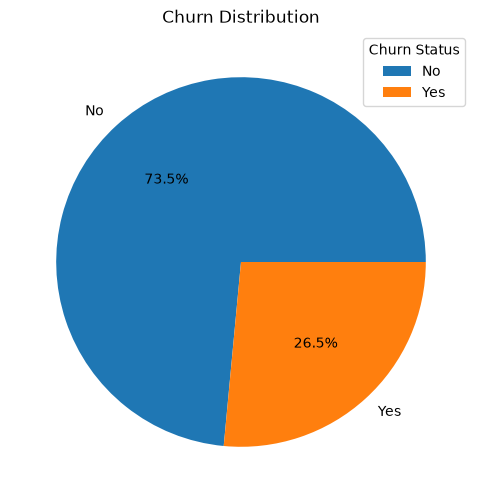

In [ ]:
# plot pie chart for churn distribution
plt.figure(figsize=(6, 6))
churn_counts = df['Churn'].value_counts()
plt.pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%')
plt.legend(title='Churn Status', loc='upper right')
plt.title('Churn Distribution')
#plt.savefig("../reports/eda/churn_distribution.png", bbox_inches="tight")
plt.show()

# calculate churn rate for baseline
churn_rate = churn_counts['Yes'] / churn_counts.sum() * 100
print(f"Churn Rate: {churn_rate:.2f}%")

**Key Insights💡**
- **Class imbalance:** The dataset exhibits a significant class imbalance. **73.4% of the customers have not churned("No")**, while **26.6% have churned("Yes")**.

## 4.2 Bivariate Analysis: Categorical features vs. Churn 

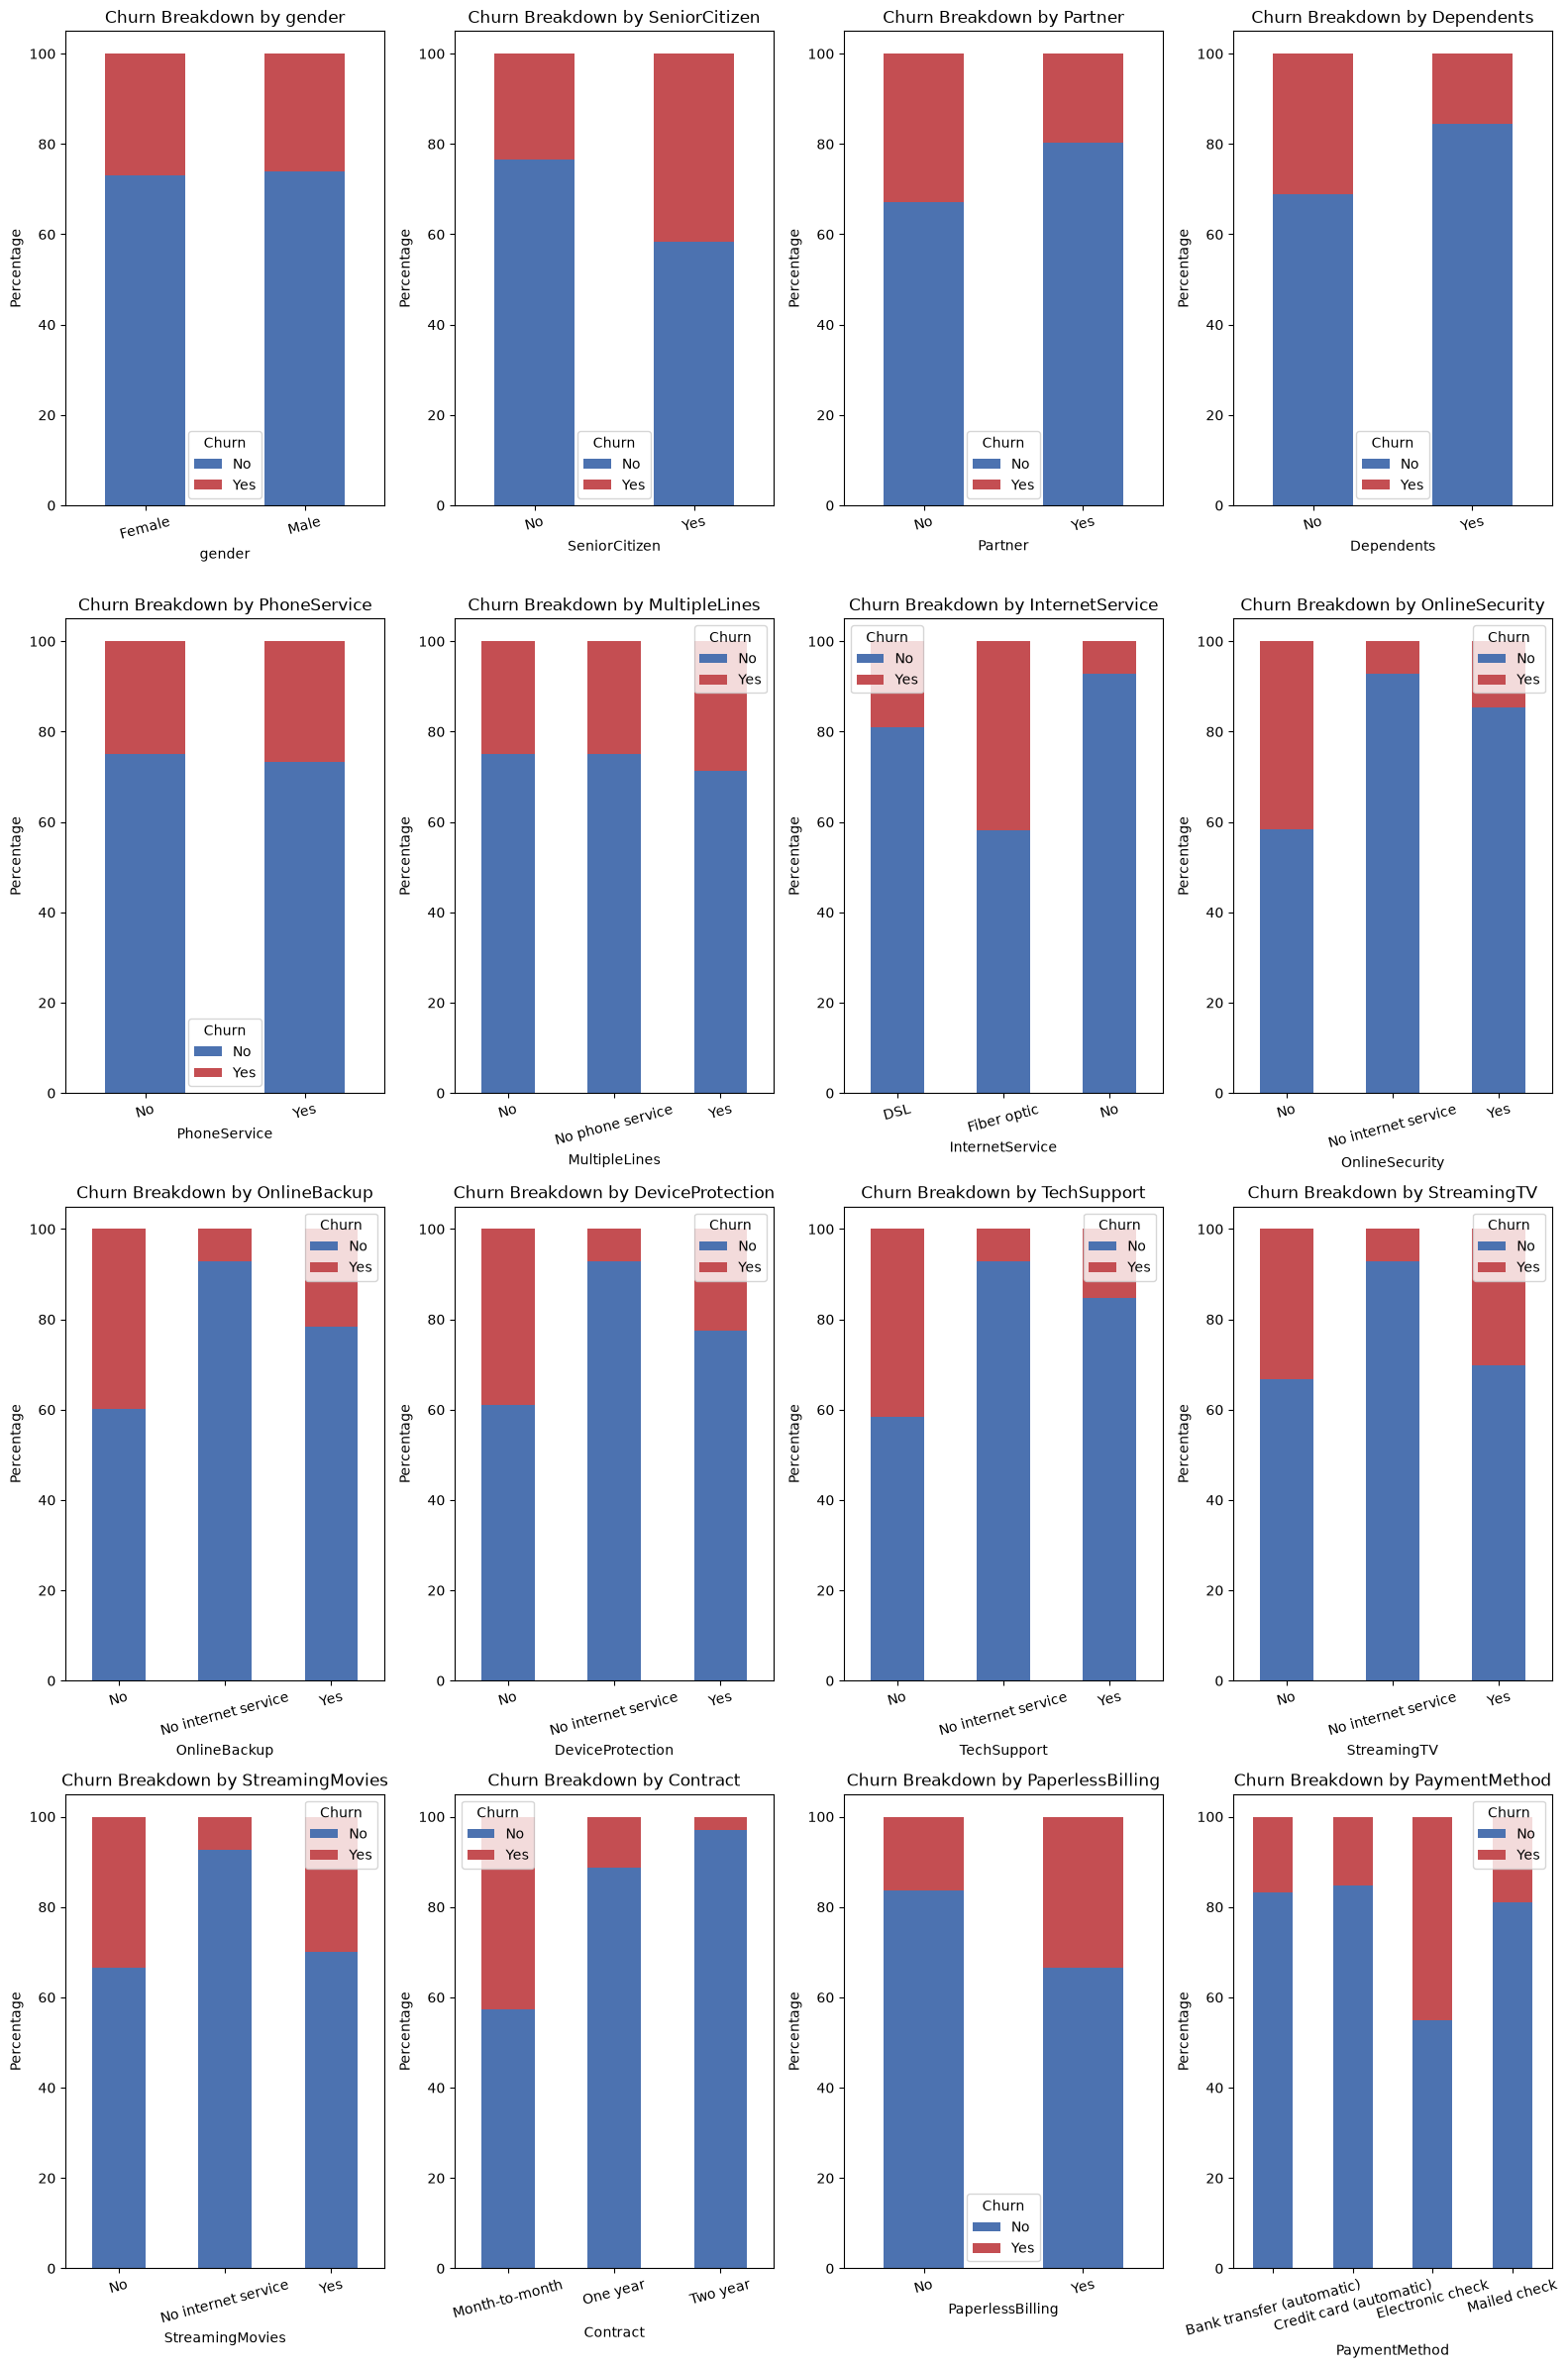

In [15]:
categorical_cols = df.select_dtypes(include='object').columns

fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,24))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    # Create a normalized percentage  plot for better risk assessment
    if col == 'Churn':
        continue

    df_plot = (
        df.groupby(col, dropna=False)['Churn']
          .value_counts(normalize=True)
          .unstack(fill_value=0) * 100
    )
    df_plot.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        color=['#4c72b0','#c44e52']
        )
    axes[i].set_title(f'Churn Breakdown by {col}')
    axes[i].set_ylabel('Percentage')
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
#plt.savefig('../reports/eda/churn_breakdown_by_categorical_features.png', bbox_inches='tight', dpi=300)
plt.show()

In [16]:
# Loop and calculate percentages
for col in categorical_cols:
    print(f"--- Churn Breakdown by {col} ---")
    percentages = (
        df.groupby(col)['Churn']
        .value_counts(normalize=True)
        .mul(100)
        .round(2)                     # Rounds to 2 decimal places for neatness
        .rename('Percentage')
        .to_frame()                   # Converts to DataFrame for better formatting
    )
    display(percentages)
    print("\n")                       # Adds a blank line between tables

--- Churn Breakdown by gender ---


Percentage
gender Churn            
Female No          73.12
       Yes         26.88
Male   No          73.89
       Yes         26.11



--- Churn Breakdown by SeniorCitizen ---


Percentage
SeniorCitizen Churn            
No            No          76.45
              Yes         23.55
Yes           No          58.37
              Yes         41.63



--- Churn Breakdown by Partner ---


...

Percentage
PaperlessBilling Churn            
No               No          83.66
                 Yes         16.34
Yes              No          66.55
                 Yes         33.45



--- Churn Breakdown by PaymentMethod ---


Percentage
PaymentMethod             Churn            
Bank transfer (automatic) No          83.27
                          Yes         16.73
Credit card (automatic)   No          84.75
                          Yes         15.25
Electronic check          No          54.85
                          Yes         45.15
Mailed check              No          80.98
                          Yes         19.02



--- Churn Breakdown by Churn ---


,Percentage
Churn,
No,100.0
Yes,100.0


### 📊 Key Insights from Categorical Feature Analysis

#### 👤 Demographics
* **Household Ties Over Gender:** Customers living alone (**No Partner** and **No Dependents**) are highly volatile, showing churn rates climbing toward **35% or higher**. Conversely, account ties to family structures drastically increase product stickiness.
* **Age Risk:** **Senior Citizens** represent a high-risk segment, churning at a significantly higher rate (roughly **40% or more**) compared to younger demographics.
* **Low Impact:** **Gender** shows virtually identical distributions between males and females, offering zero predictive power for the machine learning model.

#### 📜 Contract Type
* **The Month-to-Month Hazard:** **Month-to-month** contracts are the single largest risk factor in the dataset, driving an astronomical churn rate **well over 40%**. 
* **Long-Term Lock-In:** Churn drops off a cliff for **One-year** contracts and becomes almost non-existent for **Two-year** contracts, making this the most powerful administrative retention lever.

#### 🌐 Internet Service
* **The Fiber Optic Anomaly:** Customers with **Fiber Optic** internet service exhibit an alarmingly high churn rate, approaching **nearly 40%**. 
* **DSL & Non-Internet Stability:** **DSL** users are much more stable, while customers with no internet service at all have the lowest churn. This suggests fiber optic tiers might suffer from high premium pricing or technical/reliability issues.

#### 💳 Payment Method
* **Electronic Check Alert:** Customers paying manually via **Electronic Check** are the most volatile group in the entire dataset, with a massive churn rate approaching **nearly 50%**.
* **Autopay Stability:** Customers utilizing automated billing options—**Bank Transfer (automatic)** and **Credit Card (automatic)**—have exceptionally low churn rates because they face less recurring monthly payment friction.

#### 🛡️ Subscribed Services
* **Utility & Support Anchor Users:** Customers who do **not** subscribe to **Online Security**, **Tech Support**, **Online Backup**, or **Device Protection** experience extreme churn rates (35%+). Activating these specific utility add-ons heavily anchors customers to the ecosystem.
* **Low Impact:** Entertainment-focused add-ons like **Streaming TV** and **Streaming Movies**, alongside basic **Phone Service**, have a negligible effect on whether a user decides to leave or stay.




In [17]:
for col in categorical_cols:
    print(f"\nFrequency distribution for {col}:")
    # as percentage of total
    freq_dist = df[col].value_counts().reset_index()
    freq_dist['percentage'] = (freq_dist['count'] / freq_dist['count'].sum()) * 100
    display(freq_dist.sort_values(by='count', ascending=False))



Frequency distribution for gender:


,gender,count,percentage
0,Male,3535,50.42796
1,Female,3475,49.57204



Frequency distribution for SeniorCitizen:


,SeniorCitizen,count,percentage
0,No,5869,83.723252
1,Yes,1141,16.276748



Frequency distribution for Partner:


...

,PaperlessBilling,count,percentage
0,Yes,4158,59.315264
1,No,2852,40.684736



Frequency distribution for PaymentMethod:


,PaymentMethod,count,percentage
0,Electronic check,2359,33.651926
1,Mailed check,1588,22.653352
2,Bank transfer (automatic),1542,21.997147
3,Credit card (automatic),1521,21.697575



Frequency distribution for Churn:


,Churn,count,percentage
0,No,5153,73.509272
1,Yes,1857,26.490728


## 4.3 Numerical Feature Behaviour

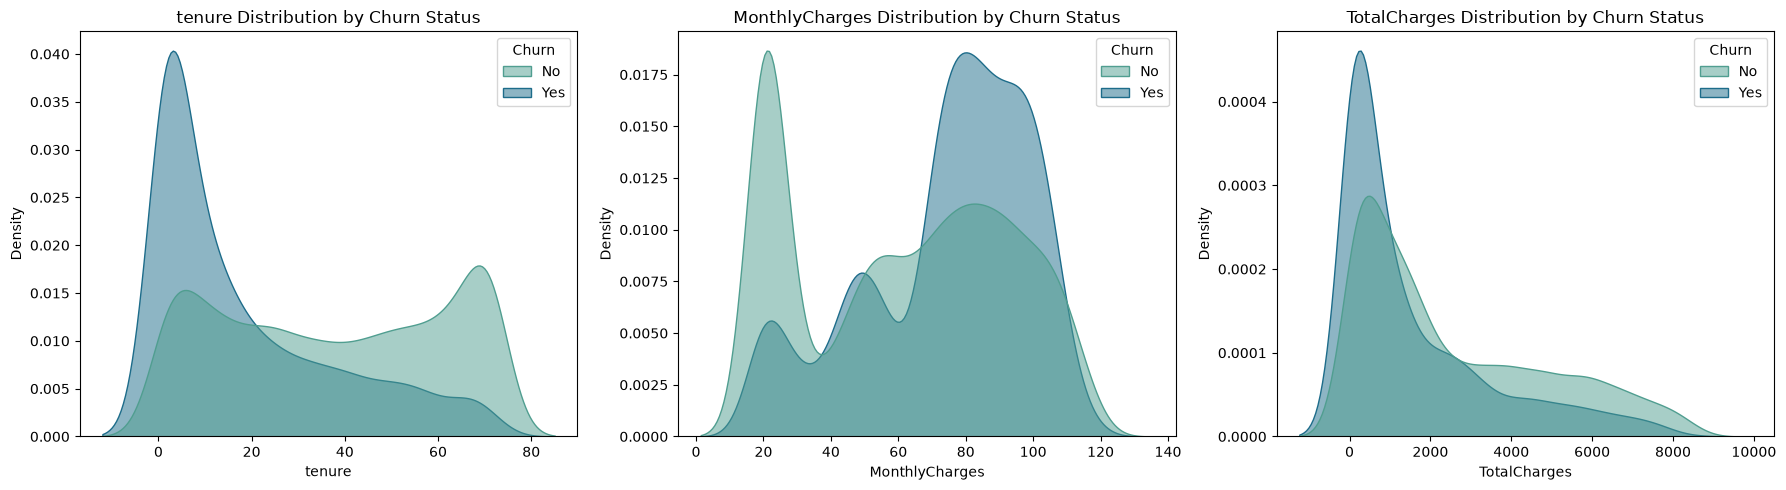

In [18]:
numerical_cols = df.select_dtypes(exclude='object').columns

fig, axes = plt.subplots(1, 3, figsize=(18,5))

for i, col in enumerate(numerical_cols):
    sns.kdeplot(data=df,
                x=col,
                hue='Churn',
                fill=True,
                common_norm=False,
                palette='crest',
                alpha=0.5,
                ax=axes[i]
                )
    axes[i].set_title(f'{col} Distribution by Churn Status')
plt.tight_layout()
#plt.savefig('../reports/eda/numerical_features_distribution_by_churn.png', dpi=300)
plt.show()

    

**Key Insights 💡**

**Tenure Distribution**
- **High Early Risk:** Customers with **low tenure(0-20 months)** show a massive spike in churn("Yes").
- **Long-Term Loyalty:** A tenure increases, the probability of churn drops significantly. Customers who cross the **60+ month mark** are highly likely to stay("No").
- **Take away:** *Onboarding and early-stage engagement* are critical to reducing overall customer loss.

**Monthly Charges Distribution**
- **Premium Price sensitivity:** Churning customers are heavily concentrated in the **higher monthly fee range($70-$110).**
- **Low-Tier stability:** Customers paying low fees ($20) have an extremely low rate of churn.
- **Take away:** Hig-paying tiers might lack a clear value proposition, leading to expensive accounts to cancel.

**Total Charges Distribution**
- **Early exits:** Churn is heavily skewed toward **very low total charges.**
- **Take away:** This reinforces the tenure insight - customers leave before they can accumulate long-term spending, indicating that high upfront or early monthly costs drive them away quickly.

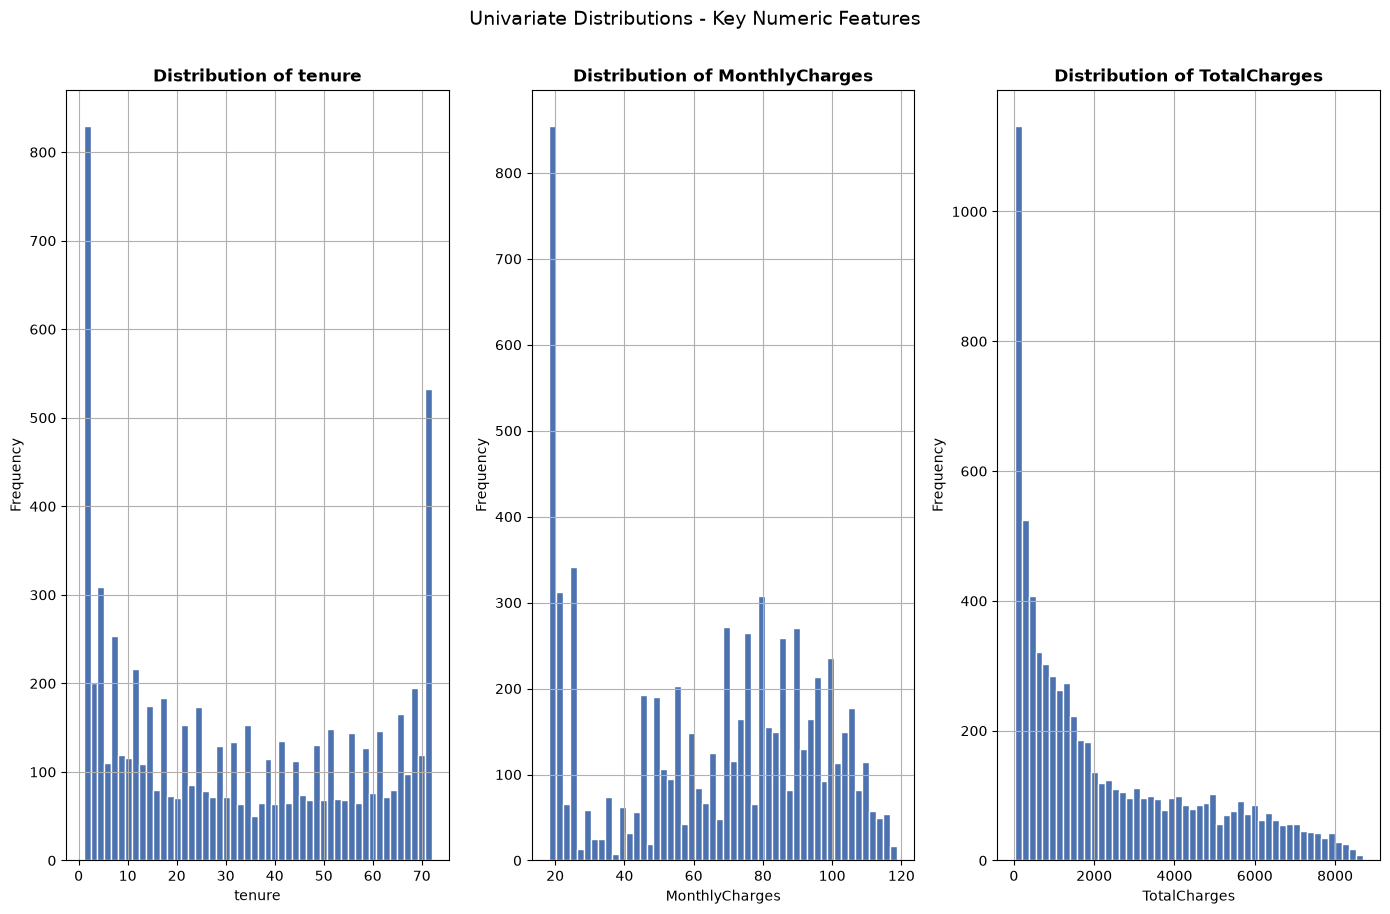

In [19]:
fig, axes = plt.subplots(1,3, figsize=(14,9))

for ax, col in zip(axes.flatten(), numerical_cols):
    df[col].hist(bins=50, ax=ax, color="#4c72b0", edgecolor="white")
    ax.set_title(f"Distribution of {col}", fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Univariate Distributions - Key Numeric Features", fontsize=14, y=1.01)
plt.tight_layout()
#plt.savefig('../reports/eda/univariate_distributions_numeric_features.png', dpi=300)
plt.show()

**Key Insights💡**
- **Distribution of tenure:** Shows high frequency for low values
- **Distribution of MonthlyCharges:** Displays varying frequwncies across charge amounts
- **Distribution of TotalCharges:** Is right-skewed, with most customers haviwng lower total charges and fewwer having higher values.

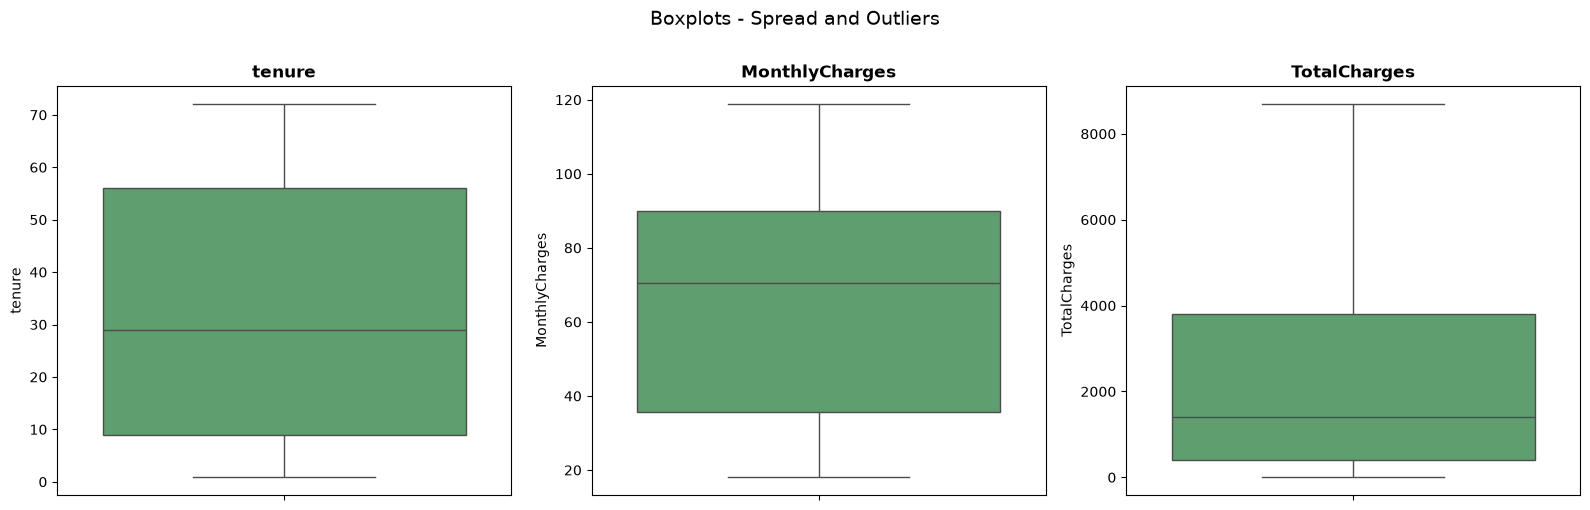

In [20]:
fig, axes = plt.subplots(1,3, figsize=(16,5))

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(y=df[col], ax=ax, color="#55a868", flierprops=dict(marker=".", alpha=0.3))
    ax.set_title(col, fontweight="bold")

plt.suptitle("Boxplots - Spread and Outliers", fontsize=14, y=1.01)
plt.tight_layout()
#plt.savefig('../reports/eda/boxplots_numeric_features.png', dpi=300)
plt.show()


**Key Insights💡**
- **No Statistical outliers:** Boxplots of the numerical variables show no obvious outliers **(no indiviual data points plotted beyond the whisker)**, suggesting the data follows a realistic distribution without extreme anomalous values.

# 5.0 Modelling

In [21]:
# Define X and y as Features and target 
X = df.drop(['Churn'], axis= 1) # Features
y = df['Churn'] # target variable




In [22]:
# convert target variable using mapping 
y = y.map({"No":0, "Yes": 1})


In [23]:
# feature
display(X.head())

# Target Variable
display(y.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

## 5.1 Train splitting and Identifying Categorical and Numerical features

In [24]:
# split the data into Train and test data first with original columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=66
)

In [25]:
categories = df.select_dtypes(include="object").columns
for col in categories:
    print(f'\n{col}:')
    display(df[col].unique())


gender:


<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str


SeniorCitizen:


<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


Partner:


...

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


PaymentMethod:


<ArrowStringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


Churn:


<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [26]:
 # identify categorical features and separate them from numerical features
categorical_features = X_train.select_dtypes(include='object').columns
print(categorical_features)

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


In [27]:
# identify numerical features nad separate them from categorical features
numerical_features = X_train.select_dtypes(exclude='object').columns
print(numerical_features)

Index(['tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')


## 5.2 Encoding Categorical Features and Scaling Numerical Features

In [28]:
# Create an encoder using OneHotEncoding & fit it on X_train features first.(categorical features) 
encoder = OneHotEncoder(handle_unknown='ignore', drop='first')

X_train_encoded = encoder.fit_transform(X_train[categorical_features])

X_test_encoded = encoder.transform(X_test[categorical_features])

# Prepare numerical features 
X_train_numerical = X_train[numerical_features]
X_test_numerical = X_test[numerical_features]

# Scale numerical features 
scaler = StandardScaler()

X_train_numerical_scaled = scaler.fit_transform(X_train_numerical)
X_test_numerical_scaled = scaler.transform(X_test_numerical)

In [29]:
# Convert X_encoded in DataFrames since they are in Series

X_train_encoded = pd.DataFrame(
    X_train_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)

# convert scaled numerics back to dataframes
X_train_numerical_scaled = pd.DataFrame(
    X_train_numerical_scaled,
    columns=numerical_features,
    index=X_train.index
)
X_test_numerical_scaled = pd.DataFrame(
    X_test_numerical_scaled,
    columns=numerical_features,
    index=X_test.index

)


In [30]:
# # view how the encoding and scaling has become
# X_train_encoded
# X_train_numerical_scaled

In [31]:
# Now Combine the dataframes  with numeric features

X_train_final = pd.concat([X_train_encoded, X_train_numerical_scaled], axis=1)
X_test_final = pd.concat([X_test_encoded, X_test_numerical_scaled], axis=1)

## 5.3 Logistic Regression Model

In [32]:
# fit the model on the training data
lr = LogisticRegression(max_iter=1000)  #class_weight='balanced'
lr.fit(X_train_final, y_train)

# predict X_test data using  trained model
y_pred = lr.predict(X_test_final)

# Make an evaluation based on the y_test
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1031
           1       0.65      0.54      0.59       371

    accuracy                           0.80      1402
   macro avg       0.75      0.72      0.73      1402
weighted avg       0.79      0.80      0.80      1402



## Metric Analysis of Logistic regression Model
- Overall Accuracy(0.80):  The model predicts 80% of all the cases in the churn dataset(1,122 out of 1402 instances)
- Class 0(majority class) Performance:
     - Precision(0.84): When it predicts instances of class 0(Not Churning), it is correct 84%  of the time.
     - Recall(0.89): It successfully captures 89% of all actuall class 0(Not churning) instances in the churn dataset.
     - F1-Score(0.87): A strong harmonic mean, proving high reliability for majority class.
- Class 1(minority class) Performance:
     - Precision(0.65): When the model flags an instance as Class 1, it is 65% correct. Meaning 35% of its Class 1 predictions are false alarms.
     - Recall(0.54): It uncovers 54% of true Class 1 instances missing nearly Half(46%) of the minority class.
     - F1-Score(0.59): A moderate score reflecting the classic struggloe of standard medels handling imbalanced data.

In [33]:
# evaluate using confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm

array([[921, 110],
       [169, 202]])

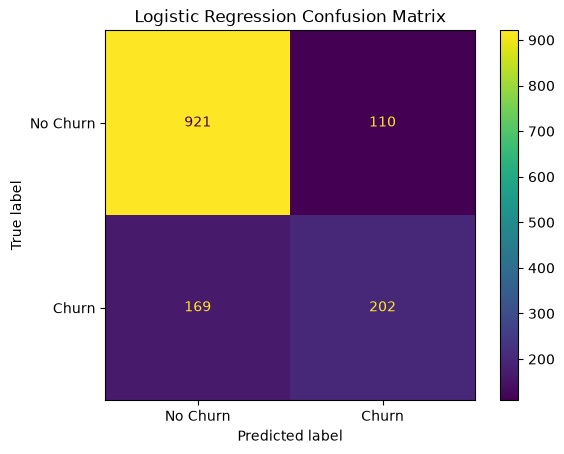

In [34]:
# plot Confusion matrix to display  what is observed

ConfusionMatrixDisplay(
    confusion_matrix= cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 5.4 Random Forest Classifier Model

In [35]:
rf = RandomForestClassifier(n_estimators=100,  random_state=42) #class_weight='balanced_subsample', max_depth=6, min_samples_leaf=10,
rf.fit(X_train_final, y_train)

y_pred =rf.predict(X_test_final)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1031
           1       0.62      0.51      0.56       371

    accuracy                           0.79      1402
   macro avg       0.73      0.70      0.71      1402
weighted avg       0.78      0.79      0.78      1402



## Metric Analysis of Random Forest Classifier
The RF model struggles more noticeably with the class imbalance, leaning heavily into the majority class to make it predictions.

- Overall Accuracy(0.79): The model correctly predicts 795 of all cases, droppeing slightly below the Logistic Regression baseline.
- Class 0(Majority Class) Performance:
      - Precison(0.84): Identical to Logistic Regression; 84% of its Class 0 predictions are accurate.
      - Recall(0.89): Identical to Logistic Regression; it catches 89% of all actual class 0 instances.
      - F1-Score(0.86): Pinpoint accurate for the majority class, slightly lower than logistic regression by 0.01.
-  Class 1(Minority Class) Performance:
      - Precision(0.62): When it predicts Class 1, it is only correct 62% of the time, yielding a higher rate of false positives(38%) than the Logistic model.
      - Recall(0.51): It only catches 51% of the actual Class 1 instances. The model has a 50% to be right or wrong in identifying a true minority case.
      - F1-Score(0.56): A noticeable weak score that demonstarate poor balance between precision and recall for your target class.

## 5.5 Features of Importance Comparison

In [36]:
# extract logistic regression coefficients and feature names
lr_impact = lr.coef_[0]

# feature of importance from random forest
rf_importance = rf.feature_importances_

# combine the feature names and their corresponding coefficients into a DataFrame
feature_names = X_train_final.columns
comparison_df = pd.DataFrame({
    'Feature' : feature_names,
    'Logistic Regression Impact': lr_impact,
    'Random Forest Importance': rf_importance 
})

# sort bt RF top features to compare them side by side
display(comparison_df.sort_values(by='Random Forest Importance', ascending=False).head(10))

,Feature,Logistic Regression Impact,Random Forest Importance
29,TotalCharges,0.856989,0.192323
27,tenure,-1.556502,0.175437
28,MonthlyCharges,-0.378386,0.163046
7,InternetService_Fiber optic,0.955465,0.040919
25,PaymentMethod_Electronic check,0.339835,0.039931
0,gender_Male,-0.021137,0.028310
10,OnlineSecurity_Yes,-0.370449,0.026467
23,PaperlessBilling_Yes,0.334459,0.026027
16,TechSupport_Yes,-0.368936,0.024967
22,Contract_Two year,-1.344183,0.024226


## Logistic Regression Impact(coefficients)
- Shows the direction, For example for tenure  it has a stong negative impact meaning as tenure increases, the probability of  churning(class 1) drops. 
- InternetService_Fibre optic strongly drives towards churrning Class 1.

## Conclusion 
- Based on the metrics Logistic regression is prefered because it has a higher precision by 3% and a higher recall by 3% for Class 1 than Random forest Classifier.
- It is more accurate at detecting churning customers.

## Tuning the Models

In [ ]:
# Tune logistic regression
# fit the model on the training data
lr_final = LogisticRegression(max_iter=1000, class_weight='balanced')  #class_weight='balanced' deals with imbalanced data
lr_final.fit(X_train_final, y_train)

# predict X_test data using  trained model
y_pred = lr_final.predict(X_test_final)

# Make an evaluation based on the y_test
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.71      0.80      1031
           1       0.51      0.82      0.63       371

    accuracy                           0.74      1402
   macro avg       0.71      0.77      0.71      1402
weighted avg       0.81      0.74      0.76      1402



## Metric Analysis of  Tuned Logistic regression Model
- Overall Accuracy(0.74):  The model predicts 74% of all the cases in the churn dataset(1,037 out of 1402 instances)
- Class 0(majority class) Performance:
     - Precision(0.92): When it predicts instances of class 0(Not Churning), it is correct 92%  of the time. Highly accurate
     - Recall(0.71): It successfully captures 71% of all actuall class 0(Not churning) instances in the churn dataset. It misclassifies 29% of them as Class 1
     - F1-Score(0.80): A strong harmonic mean, proving high reliability for majority class.
- Class 1(minority class) Performance:
     - Precision(0.51): When the model flags an instance as Class 1, it is 51% correct. Meaning 49% of its Class 1 predictions are false alarms.
     - Recall(0.82): A massive improvement. the model now successfully uncovers 82% of all true Class 1 instances in the dataset.
     - F1-Score(0.63): A harmonic balance improves significantly from its original 0.59.

In [ ]:
# tune random forest
final_rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=6,                      # Stop deep, greedy over-splitting
    min_samples_leaf=5,              # Force broader, more stable leaf nodes
    class_weight='balanced_subsample', # deals with imbalanced data
    random_state=42
)
final_rf.fit(X_train_final, y_train)
y_pred = final_rf.predict(X_test_final)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.73      0.81      1031
           1       0.52      0.82      0.64       371

    accuracy                           0.75      1402
   macro avg       0.72      0.78      0.72      1402
weighted avg       0.81      0.75      0.77      1402



## Metric Analysis of Tuned Random Forest Classifier
The RF model responded wel after some manual tuning and as a result outperformed the tuned Logistic Regression.

- Overall Accuracy(0.75): It preserves slightly more overall accuracy than tuned Logistic Regression. Correctly predicting 75% of the entire dataset.
- Class 0(Majority Class) Performance:
      - Precison(0.92): Identical to tuned Logistic Regression; 92% of its Class 0 predictions are accurate.
      - Recall(0.73):Successfully captures 73% of actual Class 0 cases - beating tuned Logistic Regression by 2% and minimizing unneccessary misclassification.
      - F1-Score(0.81): Pinpoint accurate for the majority class, slightly higher than tuned logistic regression by 1.
-  Class 1(Minority Class) Performance:
      - Precision(0.52): When it predicts Class 1, it is only correct 52% of the time, yielding a lower rate of false positives(488%) than the Logistic model.
      - Recall(0.82): It  catches 82% of the actual Class 1 instances.It matches with the tuned Logistic regression
      - F1-Score(0.64):It yields the highest, most balanced minority metric across both models.

In [39]:
lr_final_impact = lr_final.coef_[0]

final_rf_importance = final_rf.feature_importances_

comparison_df1 = pd.DataFrame({
    'Feature' :feature_names,
    'Logistic Regression Impact': lr_final_impact,
    'Random Feature of importance': final_rf_importance
})

display(comparison_df1.sort_values(by='Random Feature of importance', ascending=False).head(10))

,Feature,Logistic Regression Impact,Random Feature of importance
27,tenure,-1.494318,0.205252
29,TotalCharges,0.841360,0.116207
7,InternetService_Fiber optic,0.976785,0.104799
22,Contract_Two year,-1.441861,0.103003
25,PaymentMethod_Electronic check,0.338595,0.068320
28,MonthlyCharges,-0.465243,0.055536
8,InternetService_No,-0.173786,0.046413
21,Contract_One year,-0.701041,0.039587
10,OnlineSecurity_Yes,-0.342591,0.033854
16,TechSupport_Yes,-0.330838,0.028444


## Conclusion 
- The tuned RF model performs better than the tuned Logistic model because it will give fewer false positives.
- Final_rf is to be produced and deployed.

# 6.0 Production And Deployment

## 6.1 Save file to joblib

In [40]:
import joblib

# Saved the tuned trained Random Forest Model
joblib.dump(final_rf, "final_rf.pkl")

# Save the OnehotEncoder
joblib.dump(encoder, "encoder.pkl")

# Save the StandardScaler
joblib.dump(scaler, "scaler.pkl")

# Save the exact feature names and order used by the model
feature_names = X_train_final.columns.to_list()
joblib.dump(feature_names, "feature_names.pkl")

print("All files are saved successfully.")

All files are saved successfully.


In [41]:
feature_names

['gender_Male',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'PhoneService_Yes',
 'MultipleLines_No phone service',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_No internet service',
 'OnlineSecurity_Yes',
 'OnlineBackup_No internet service',
 'OnlineBackup_Yes',
 'DeviceProtection_No internet service',
 'DeviceProtection_Yes',
 'TechSupport_No internet service',
 'TechSupport_Yes',
 'StreamingTV_No internet service',
 'StreamingTV_Yes',
 'StreamingMovies_No internet service',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check',
 'tenure',
 'MonthlyCharges',
 'TotalCharges']

In [42]:
# create streamlit app

app_code = '''

import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Define the numerical and categorical features
numerical_features = ['tenure','MonthlyCharges','TotalCharges']
categorical_features = ['gender','SeniorCitizen','Partner','Dependents','PhoneService','MultipleLines','InternetService','OnlineSecurity',
                        'OnlineBackup',	'DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaperlessBilling',
                        'PaymentMethod']

#  Load the saved model and preprocessing tools
final_rf = joblib.load("final_rf.pkl")
encoder = joblib.load("encoder.pkl")
scaler = joblib.load("scaler.pkl")
feature_names= joblib.load("feature_names.pkl")

# Streamlit page settings
st.set_page_config(page_title="Customer Churn Prediction", page_icon="📊", layout="centered")

# App title
st.title("📊Customer Churn Prediction")
st.write("Enter the Customer's information below to predict the likelihood of churn")
st.info("This application is for educational and demonstration purposes." "It requires further testing to be approved as a customer churn predictor")

st.divider()

st.subheader("Customer Informationℹ️")
# Create User input fields
gender = st.selectbox("Gender", ["Female","Male"])

senior_citizen = st.selectbox("Are you a seniour citizen?",["No", "Yes"])

partner = st.selectbox("Do you have a partner?", ["No", "Yes"])

dependents = st.selectbox("Do you have dependents?", ["No", "Yes"])

tenure = st.number_input("How many months have you been with IBM?", min_value=0, max_value=100, value=12)

monthly_charges = st.number_input("Monthly Charges", min_value=0.0, value=50.0)

total_charges = st.number_input("Total Charges", min_value=0.0, value=600.0)

# service inputs
st.subheader("Additional Services")

phone_services =  st.selectbox("Do you have a phone service?",['No', 'Yes'])   

multiple_lines = st.selectbox("Do you have multiple lines?",['No phone service', 'No', 'Yes'])

internet_service = st.selectbox("Do you have internet service?",['DSL', 'Fiber optic', 'No'])

online_security = st.selectbox("Do you have online security?", ['No', 'Yes', 'No internet service'])

online_backup = st.selectbox("Do you have online backup?", ['Yes', 'No', 'No internet service'])

device_protection = st.selectbox("Do you have device protection?",['No', 'Yes', 'No internet service'])

tech_support = st.selectbox("Do you have tech support?", ['No', 'Yes', 'No internet service'])

streaming_tv = st.selectbox("Do you have streaming tv services?",['No', 'Yes', 'No internet service'])

streaming_movies = st.selectbox("Do you have streaming movies services?", ['No', 'Yes', 'No internet service'])

# Contract and Billing information

st.subheader("Contract & Billing")
contract = st.selectbox("Which contract have you subscribeed to?",['Month-to-month', 'One year', 'Two year'])

paperless_billing = st.selectbox("Do you use paperless billing",["No", "Yes"] )

payment_method = st.selectbox("How do you pay for IBM?", ['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'])

# Create input data for the model
input_data = pd.DataFrame({
    "gender": [gender],
    "SeniorCitizen": [senior_citizen],
    "Partner": [partner],
    "Dependents": [dependents],
    "tenure": [tenure],
    "MonthlyCharges": [monthly_charges],
    "TotalCharges": [total_charges],
    "PhoneService": [phone_services],
    "MultipleLines": [multiple_lines],
    "InternetService": [internet_service],
    "OnlineSecurity": [online_security],
    "OnlineBackup": [online_backup],
    "DeviceProtection": [device_protection],
    "TechSupport": [tech_support],
    "StreamingTV": [streaming_tv],
    "StreamingMovies": [streaming_movies],
    "Contract": [contract],
    "PaperlessBilling": [paperless_billing],
    "PaymentMethod": [payment_method]     
})

# include encoder and scaler
# separate categorical and numerical features

input_categorical = input_data[categorical_features]
input_numerical = input_data[numerical_features]

# encode categorical features
input_categorical_encoded = encoder.transform(input_categorical)

input_categorical_encoded = pd.DataFrame(
    input_categorical_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features)
)

# scale numerical features
input_numerical_scaled = scaler.transform(input_numerical)

input_numerical_scaled = pd.DataFrame(
    input_numerical_scaled,
    columns=numerical_features
)

# Combine numerical and categorical features
input_final = pd.concat([input_numerical_scaled, input_categorical_encoded], axis=1)

# Ensure features are in the  exact same order
input_final = input_final[feature_names] 

# Prediction
st.divider()
if st.button("Predict Churn", use_container_width=True):
    # Make prediction 
    prediction = final_rf.predict(input_final)[0]

    # Get Churn probability
    probability = final_rf.predict_proba(input_final)[0][1]

    # Display results
    if prediction == 1:
        st.error("The customer is likely to Churn.")

        st.write(
            f"Estimated probability of Churn:"
            f"**{probability * 100:.2f}**"
        )

    else:
        st.success("The customer is likely to stay.")

        st.write(
            f"Estimate probability of churn:"
            f"**{probability * 100:.2f}**"
        )
'''
# create the app.py file
with open("Churn_app.py", 'w', encoding="utf-8") as file:
          file.write(app_code)

print("Churn_app.py created successfully.")

Churn_app.py created successfully.


# 7.0 Business Recommendations 💡
To maximize customer retention, the business should pivot away from broad demographic targeting (like gender) or entertainment adjustments, and aggressively focus on three operational pillars:

1. **Contract & Payment Migration:** Actively incentivize **Month-to-Month** and **Electronic Check** users to transition to **Fixed-Term Contracts (1 or 2 years)** and **Automated Billing (Autopay via Credit Card/Bank Transfer)**. This operational shift addresses the two highest churn-correlated segments in the dataset.
2. **Value Optimization for Fiber Optic Tiers:** Investigate the underlying causes of the high **Fiber Optic** churn rate (e.g., potential technical issues, price hikes, or customer onboarding friction) to match its retention performance with DSL.
3. **Strategic Service Bundling:** Target high-risk accounts by bundling critical utility features—specifically **Tech Support** and **Online Security**—into standard packages, as these services act as the primary anchors for long-term customer stickiness.

